# AST 326: Exoplanet Transits
### Tutorial 2A - Generate Photometry for Standard Stars
- Primary Authors: Jacob Taylor, Bethany Ludwig
- Last Revision: February 2024
  
### Overview of the Lab:  

The goal of this lab is to detect an exoplanet and measure its properties. 

The overall schedule for this lab is as follows: 

1) Reduce your data, source detection, image motion, aperture photometry (Feb 5)

2) Brightness corrections (differential photometry), create a light curve (Feb 12)

3) Reading week (Feb 19)
  
4) Model our light curve to determine exoplanet properties (Feb 26)

5) Open work session (March 4) 

6) Report Due (March 11)  
  
### This Week:  
In the last notebook we found astrometric corrections for the stars in the image. We also generated a light curve for one of those stars.  
  
Now we will apply that process to a bunch of "standard stars" so we can correct for the brightness variations we saw in the last notebook.  
  
This lab will be in two parts:  
  
A. Generate the photometry for a bunch of standard stars  
B. Create a differential light curve so we can standardize the brightness in each image  

In [1]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
import numpy as np
import matplotlib.pyplot as plt
import glob
import sys
sys.path.append('Lib/')
import ta_funcs_transit as ta
# Set matplotlib font to be publication quality
# If this gives you issues just comment it out
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.serif"] = "Computer Modern Roman"

# Load in the target files, darks, flats
# ⚠️ Note!!! This is a LOT of data. ⚠️
# Depending on your computer, you may experience memory problems if loading all these files in at once, (i.e. your computer gets slow or crashes). 
# If that happens, you can load them in one at a time in the get_positions_and_photometry function the same way we did in the first notebook.   
target_files =[f'Data/r{file_n}.fit' for file_n in range(1599579, 1599942+1)]
dark = np.load("Lib/dark.npy")
flat = np.load("Lib/flat.npy")

# Open the files
all_data = [fits.open(file)[1].data for file in target_files]
headers = [fits.open(file)[0].header for file in target_files]

# Clean the observation
cleaned_data = [ta.clean_image(im, dark, flat) for im in all_data]

# I find it convenient to reset the values in the outside circle back to nan
# You can see why I choose this value if you plot a histogram of the first in all_data
for i in range(len(cleaned_data)):
    cleaned_data[i][all_data[0] < 725] = 0
    cleaned_data[i][cleaned_data[i] == 0] = np.nan
    

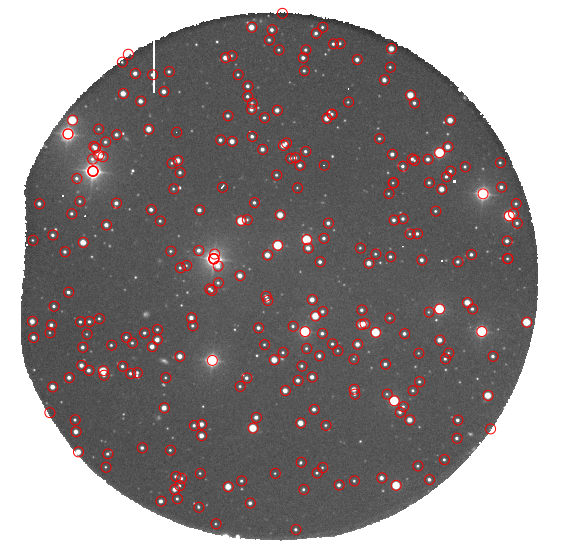

In [2]:
# Open the first cleaned image
data0 = cleaned_data[0]

# Plot the image
vmin,vmax = ZScaleInterval().get_limits(data0)
plt.figure(figsize=(10,10))
plt.imshow(data0, cmap='gray', origin='lower',vmin=vmin,vmax=vmax)

# Use your source detection algorithm to get the positions and plot them

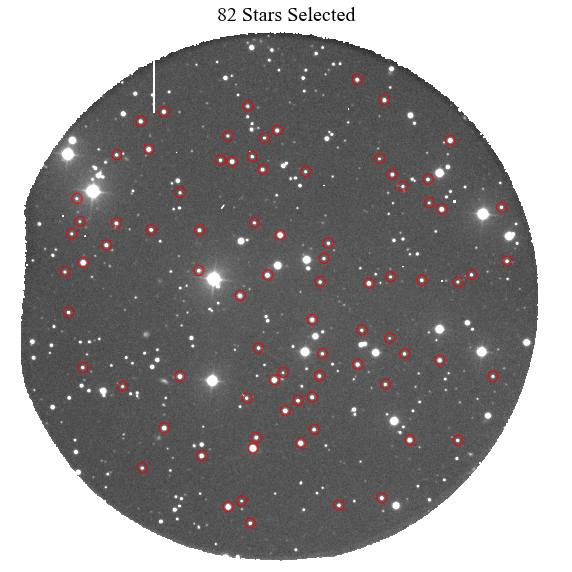

In [3]:
# We don't want to include any tricky stars, for instance: 
# - Stars close to the edge 
# - Stars overlapping bad pixels (notice line near the top)
# - Stars that are saturated (cross behavior)
# - Stars that are too close to each other
# - Stars that are faint
# It might help you to plot a histogram of the values in the image to set appropriate thresholds
# You would use something like: plt.hist(data0.flatten(),bins=100,range=(0,200))

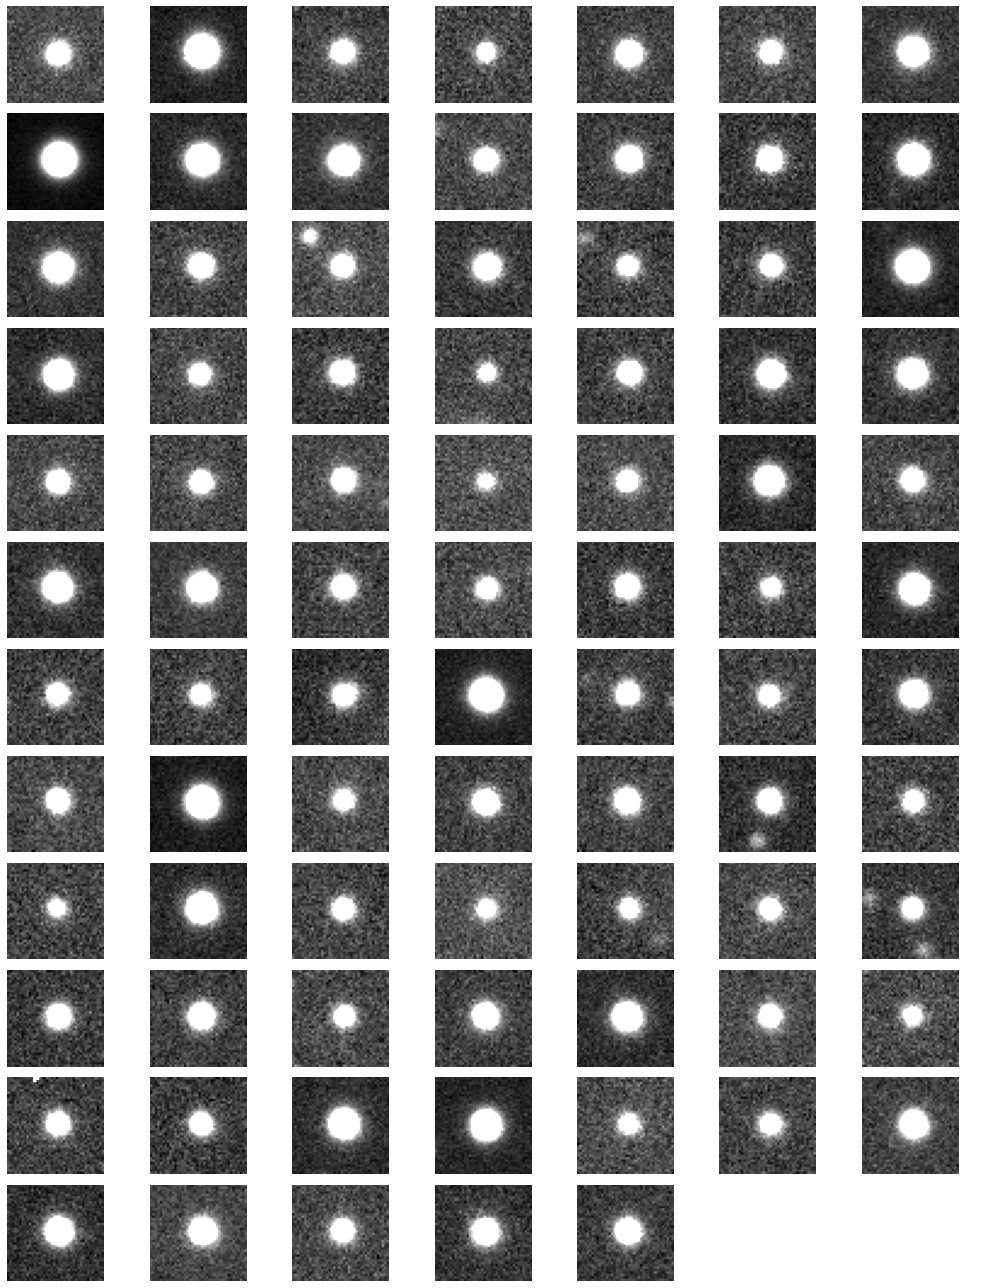

In [4]:
# Zoom in on each star to make sure you like them 
# You can choose to exclude any stars you don't like 
# Ideally they are fairly isolated, symmetric, and don't have abberations 

In [5]:
# Load in the movement vector (How much the star jumps around) that you calculated in the last lab
vector = np.loadtxt('MovementVectors/movementvector.txt')
vector_xs = vector[:,1]
vector_ys = vector[:,0]

# If you set a limit on how close your stars could be to each other, then you can use that to pick a box size that will only include your target star 
boxsize=20

# Set your aperture photometry parameters 
aperture_radius = 5.5
annulus_radius_inner = 12
annulus_radius_outer = 18
GAIN = 1.16

# We want to run the code we built in the lab on all of the stars so lets put it into a function
# If you're having trouble getting it to work, take it out of the function and do one star, make a plot for each step
# Alternatively scratch all this and do it your own way :)
def get_positions_and_photometry(x,y):
    # Containers 
    positions = []
    fluxes = []
    flux_errors = []
    # Loop over each image 
    for data, vector_x, vector_y in zip(cleaned_data, vector_xs, vector_ys):
        # Correct our position with our vector correction
        tracked_x, tracked_y = int(np.round(x + vector_x,0)), int(np.round(y + vector_y,0))

        # Make a box around the new position
        box = data[tracked_y-boxsize: tracked_y+boxsize+1, 
                tracked_x-boxsize: tracked_x+boxsize+1].copy()

        # The tracking in the last lab isn't perfect so recalculate the centroid of the star within that box
        new_box_x, new_box_y =  ta.centroid(box)

        # Convert to the full image coordinates
        new_x = tracked_x + new_box_x - boxsize
        new_y = tracked_y + new_box_y - boxsize
        positions.append((new_x,new_y)) 

        # Convert to integers for indexing
        new_x, new_y = int(np.round(new_x,0)), int(np.round(new_y,0))
        
        # Recenter the box
        new_box = data[new_y-boxsize: new_y+boxsize, 
                    new_x-boxsize: new_x+boxsize].copy()

        # Do the aperture photometry
        aperture = ta.get_aperture(new_box.shape, aperture_radius) 
        annulus = ta.get_annulus(new_box.shape,annulus_radius_inner,annulus_radius_outer)
        flux, flux_err = ta.get_flux(new_box, aperture, annulus, gain = GAIN)

        # Store the flux and error
        fluxes.append(flux)
        flux_errors.append(flux_err)

    # Normalize the flux and error 
    normalized_flux = fluxes / np.median(fluxes)   
    normalized_flux_err = flux_errors / np.median(fluxes)

    # Return normalized flux and error and positions
    return normalized_flux, normalized_flux_err, positions

# Check one star to make sure this works before applying to all of them 
normalized_flux, normalized_flux_err, positions = get_positions_and_photometry(standard_x[0],standard_y[0])

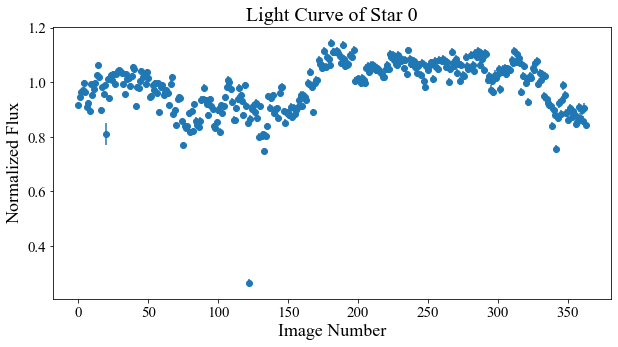

In [6]:
# Check out your light curve to make sure it makes sense 
# Do you see that one point that is very off? 

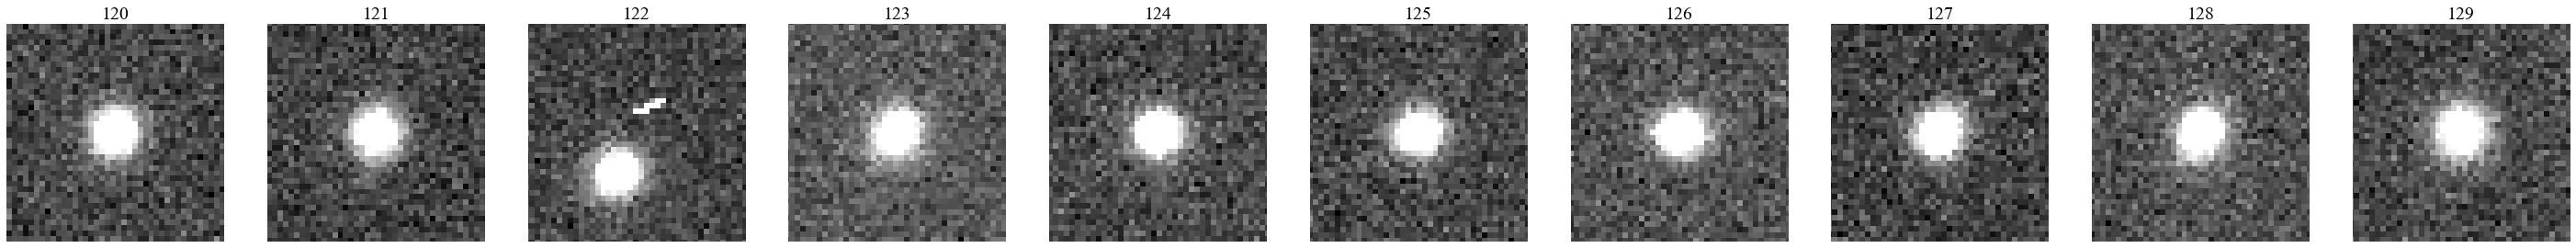

In [7]:
# Switch between the images to see if it's a you problem or a data problem

# You see that bright streak in 122? Could be a cosmic ray, could be a satellite, could be star link. Whatever it is it's messing up our centroid algorithm so the star isn't centered.
# It's up to you how you want to deal with things like this. You could remove the point, the image, you could try to fix the centroiding, or you write an algorithm to find outliers and not include them.

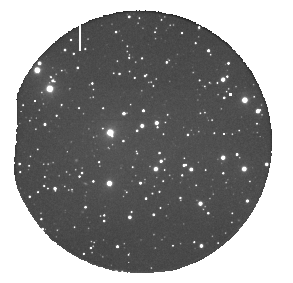

In [8]:
# The corresponding image doesn't look that bad, so it's a random fluke, not the image itself

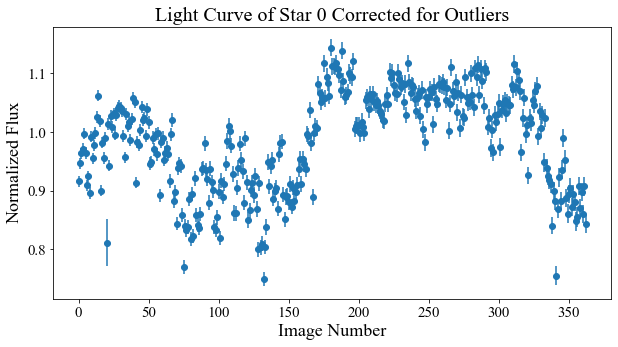

In [9]:
# This is how I would handle outliers, but there are many ways to do it
# You can read about this method here: https://www.kaggle.com/discussions/general/382825
def mad(values):
    """
    Returns the modified Z-score of all points in the array. This is defined as:
    Zm = 0.6745 * (xi - median(xi))/MAD
    where the MAD is the median average deviation defined as:
    MAD = median(abs(xi - median(xi)))
    """
    median = np.median(values)
    distances = values - median
    mad = np.median(abs(distances))

    zm = 0.6745 * distances / mad 
    return np.abs(zm)



In [10]:
# We have everything we need now to apply this to all of the stars
# It's a lot of things to keep track of so I recommend storing your data in your favorite way

# The first thing I want to store which is the same for all stars, is the time of the observations 
dates = [fits.open(file)[0].header['DATE-OBS'] for file in target_files]
times = [fits.open(file)[0].header['UTSTART'] for file in target_files]

# Put in timedate format
from datetime import datetime
dates = [datetime.strptime(d + ' ' + t.split('.')[0], '%Y-%m-%d %H:%M:%S') for d, t in zip(dates, times)]

# Convert to JD
from astropy.time import Time
julian_dates = Time(dates).jd

# Normalize
julian_dates -= julian_dates[0]

# Convert to hours, you can change this unit to whatever you want now or later
julian_dates *= 24*60

# Now we can loop over all of the stars and store the data
# This may take a few minutes, for me it was about 2-3 minutes
import pandas as pd 
for x, y in zip(standard_x, standard_y):
    
    normalized_flux, normalized_flux_err, positions = get_positions_and_photometry(x,y)
    
    # Use your favorite way to store the data
    data = {'time': julian_dates, 'flux': normalized_flux, 'flux_err': normalized_flux_err}
    df = pd.DataFrame(data)

    # Calculate outliers if you'd like
    zscore = mad(normalized_flux)
    
    # Remove outliers
    df.loc[(zscore > 3.5) | (zscore < -3.5), 'flux'] = np.nan
    df.loc[(zscore > 3.5) | (zscore < -3.5), 'flux_err'] = np.nan

    # I'm naming by the position in the first image in case you need to reference it later to know which star is which
    # The :0.1f is just so we dont have a bunch of decimal places
    df.to_csv(f'Photometry/star_{x:0.1f}_{y:0.1f}.csv', index=False)
